# Miniproject 1

### Goals for this miniproject
1. Understand how to load, index and query data using Pandas
2. Use scipy to perform hypothesis testing
3. Use Seaborn to produce a nice looking figure
4. Reproduce results from a publication
---
### How to use this notebook during class
- Follow along as we go
- Use your **Cards** to indicate where you're at:
    - A **🟩Green card** means you are caught up with Max and **ready to help your classmates**
    - A **🟥Red card** means you are stuck and need help
- <span style='color:red;'>EXERCISE</span> — work on this problem by yourself, or try with a partner if you get stuck
---


First let's import some libraries we will use today

!pip install _package_name_ 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

## 1) Load the data

We're going to do a simple example analysis on some RT qPCR data

I sort of randomly selected the qPCR data here:

https://figshare.com/articles/dataset/qPCR_data_xlsx/13079537?file=25034471

which is from this paper:
https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0243626


In [4]:
ct_data = pd.read_csv('heffer_qpcr.csv', header=1, index_col=0)
ct_data

,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh
Sample,,,,,,,
Uninjected #1,28.62,26.740,24.08,27.67,33.43,30.74,20.45
Uninjected #1,28.93,26.760,23.96,27.87,33.36,30.59,20.43
Uninjected #1,28.88,26.590,23.91,27.94,33.69,30.53,20.55
Uninjected #2,29.15,27.410,24.43,28.01,32.68,31.44,20.31
Uninjected #2,29.28,27.430,24.28,28.14,33.08,31.23,20.30
Uninjected #2,29.09,27.270,24.09,28.29,32.74,31.21,20.62
Uninjected #3,28.41,26.900,23.74,27.32,33.66,31.05,20.18
Uninjected #3,28.28,26.940,23.50,27.31,33.58,30.54,20.18
Uninjected #3,28.53,26.750,23.34,27.40,33.59,30.38,20.43


### Understanding the data
- The data are Ct (cycle threshold) values. Smaller Ct values means more transcripts are present in the sample.
- Columns are the six genes whose expression levels were measured. Gapdh is a "housekeeping gene" and serves as an endogeneous control
- Samples with the same sample label are **technical replicates**

## 2) Compute relative expression levels for each treatment and gene
Use Pandas to do some standard qPCR calculations:
1. Average across technical replicates
2. Compute $\Delta$Ct by subtracting the gene Ct values from the endogenous control, Gapdh. This result should be a Pandas DataFrame - call it `delta_ct`
4. Compute $\Delta$$\Delta$Ct by subtracting the $\Delta$Ct values for the uninjected control from each sample's $\Delta$Ct value - call this DataFrame `dd_ct`
5. Compute the relative expression levels for experimental conditions vs. controls
* To compute relative expression from $\Delta \Delta$ Ct, use this formula:
* relative expression = 2^$\Delta \Delta$ Ct

In [33]:
aggregated_ct = ct_data.groupby('Sample').agg('mean')
delta_ct = aggregated_ct.sub(aggregated_ct['Gapdh'], axis=0)
control_rows = delta_ct.filter(like='Uninjected', axis=0)
control_mean = control_rows.mean()
dd_ct = delta_ct.sub(control_mean, axis=1)
relative_expression = 2 ** -dd_ct
display(aggregated_ct)
display(delta_ct)
display(dd_ct)
display(relative_expression)

,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh
Sample,,,,,,,
DMSO/RPE #1,28.570000,27.593333,23.243333,27.526667,32.873333,29.443333,21.016667
DMSO/RPE #2,30.600000,29.416667,26.096667,31.450000,35.786667,31.990000,24.533333
DMSO/RPE #3,30.526667,27.283333,26.143333,29.713333,34.150000,32.753333,23.363333
DMSO/RPE #4,28.410000,27.950000,25.953333,30.066667,33.883333,30.023333,22.986667
DMSO/RPE #5,28.580000,28.310000,27.146667,29.746667,33.626667,29.530000,23.306667
SNC only #1,29.303333,27.910000,24.703333,28.180000,34.013333,30.443333,20.603333
SNC only #2,28.383333,26.383333,23.780000,27.833333,34.106667,30.446667,20.213333
SNC only #3,28.000000,30.073000,25.326667,29.660000,35.613333,32.266667,21.996667
SNC only #4,30.076667,27.820000,25.886667,29.360000,35.943333,32.223333,22.090000


,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh
Sample,,,,,,,
DMSO/RPE #1,7.553333,6.576667,2.226667,6.510000,11.856667,8.426667,0.0
DMSO/RPE #2,6.066667,4.883333,1.563333,6.916667,11.253333,7.456667,0.0
DMSO/RPE #3,7.163333,3.920000,2.780000,6.350000,10.786667,9.390000,0.0
DMSO/RPE #4,5.423333,4.963333,2.966667,7.080000,10.896667,7.036667,0.0
DMSO/RPE #5,5.273333,5.003333,3.840000,6.440000,10.320000,6.223333,0.0
SNC only #1,8.700000,7.306667,4.100000,7.576667,13.410000,9.840000,0.0
SNC only #2,8.170000,6.170000,3.566667,7.620000,13.893333,10.233333,0.0
SNC only #3,6.003333,8.076333,3.330000,7.663333,13.616667,10.270000,0.0
SNC only #4,7.986667,5.730000,3.796667,7.270000,13.853333,10.133333,0.0


,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh
Sample,,,,,,,
DMSO/RPE #1,-0.790833,0.109167,-1.435000,-0.915833,-1.253333,-2.006667,0.0
DMSO/RPE #2,-2.277500,-1.584167,-2.098333,-0.509167,-1.856667,-2.976667,0.0
DMSO/RPE #3,-1.180833,-2.547500,-0.881667,-1.075833,-2.323333,-1.043333,0.0
DMSO/RPE #4,-2.920833,-1.504167,-0.695000,-0.345833,-2.213333,-3.396667,0.0
DMSO/RPE #5,-3.070833,-1.464167,0.178333,-0.985833,-2.790000,-4.210000,0.0
SNC only #1,0.355833,0.839167,0.438333,0.150833,0.300000,-0.593333,0.0
SNC only #2,-0.174167,-0.297500,-0.095000,0.194167,0.783333,-0.200000,0.0
SNC only #3,-2.340833,1.608833,-0.331667,0.237500,0.506667,-0.163333,0.0
SNC only #4,-0.357500,-0.737500,0.135000,-0.155833,0.743333,-0.300000,0.0


,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh
Sample,,,,,,,
DMSO/RPE #1,1.730074,0.927123,2.703822,1.886659,2.383916,4.018527,1.0
DMSO/RPE #2,4.848371,2.998346,4.282144,1.423228,3.621699,7.871653,1.0
DMSO/RPE #3,2.267077,5.846203,1.842503,2.107939,5.004873,2.060984,1.0
DMSO/RPE #4,7.572834,2.836608,1.618884,1.270885,4.637455,10.531702,1.0
DMSO/RPE #5,8.402586,2.759041,0.883723,1.980457,6.916298,18.507011,1.0
SNC only #1,0.781418,0.558966,0.737987,0.900730,0.812252,1.508729,1.0
SNC only #2,1.128312,1.229013,1.068065,0.874078,0.581023,1.148698,1.0
SNC only #3,5.065952,0.327863,1.258466,0.848214,0.703847,1.119872,1.0
SNC only #4,1.281204,1.667284,0.910670,1.114065,0.597358,1.231144,1.0


Once you have computed relative expression, I suggest labeling each sample by a sample type. This will make it easier to plot and to do stats later. Add a column to your relative expression dataframe that lists the `sample_type` for each seample.

For example, all the samples "DMSO/RPE #1", "DMSO/RPE #2"... would be assigned a `sample_type` of "DMSO/RPE"

In [48]:
sample_type = [x.split(' #')[0] for x in relative_expression.index]
relative_expression['sample_type'] = sample_type
relative_expression

,Fn1,Col1a1,Acta2,TgfB,Tnfa,Mcp1,Gapdh,sample_type
Sample,,,,,,,,
DMSO/RPE #1,1.730074,0.927123,2.703822,1.886659,2.383916,4.018527,1.0,DMSO/RPE
DMSO/RPE #2,4.848371,2.998346,4.282144,1.423228,3.621699,7.871653,1.0,DMSO/RPE
DMSO/RPE #3,2.267077,5.846203,1.842503,2.107939,5.004873,2.060984,1.0,DMSO/RPE
DMSO/RPE #4,7.572834,2.836608,1.618884,1.270885,4.637455,10.531702,1.0,DMSO/RPE
DMSO/RPE #5,8.402586,2.759041,0.883723,1.980457,6.916298,18.507011,1.0,DMSO/RPE
SNC only #1,0.781418,0.558966,0.737987,0.900730,0.812252,1.508729,1.0,SNC only
SNC only #2,1.128312,1.229013,1.068065,0.874078,0.581023,1.148698,1.0,SNC only
SNC only #3,5.065952,0.327863,1.258466,0.848214,0.703847,1.119872,1.0,SNC only
SNC only #4,1.281204,1.667284,0.910670,1.114065,0.597358,1.231144,1.0,SNC only


## 3) Reproduce a figure in the paper
Look up the documentation for seaborn **barplot** to reproduce one of the panels from Figure 4B or C in the paper using the dataframe **relative_quantity**

https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0243626

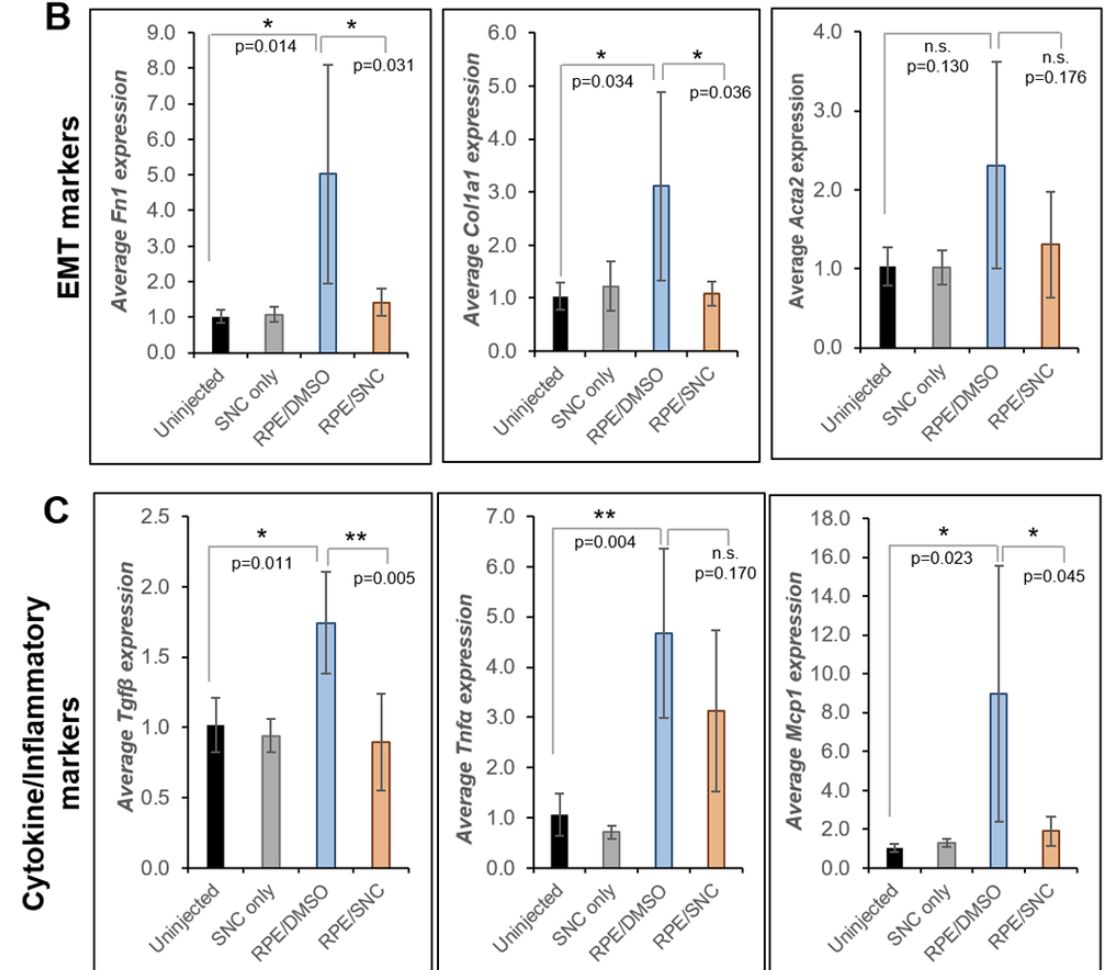

## 4) Test for a statistically significant effect of treatment
Use scipy (imported above) to perform a statisical test for the effect of treatment on gene expression. Decide which test is appropriate, look up the implementation, and apply it to the data for the gene you are plotting. Add any calculated statistics or p-values to your figure legend.

Here is a useful list of hypothesis tests that scipy can perform: https://docs.scipy.org/doc/scipy/reference/stats.html#hypotests

## 5) BONUS - plot all the sub-panels in Figure 4B & C

Use a for-loop, looping over all six genes, to plot the figure panels above in a 2 x 3 grid of plots.

To get you started I have included a subplots() call that will make the 2 x 3 grid of axis objects


Genes being plotted: ['Fn1', 'Col1a1', 'Acta2', 'TgfB', 'Tnfa', 'Mcp1']
Available conditions: ['RPE/DMSO', 'RPE/SNC', 'SNC only', 'Uninjected']


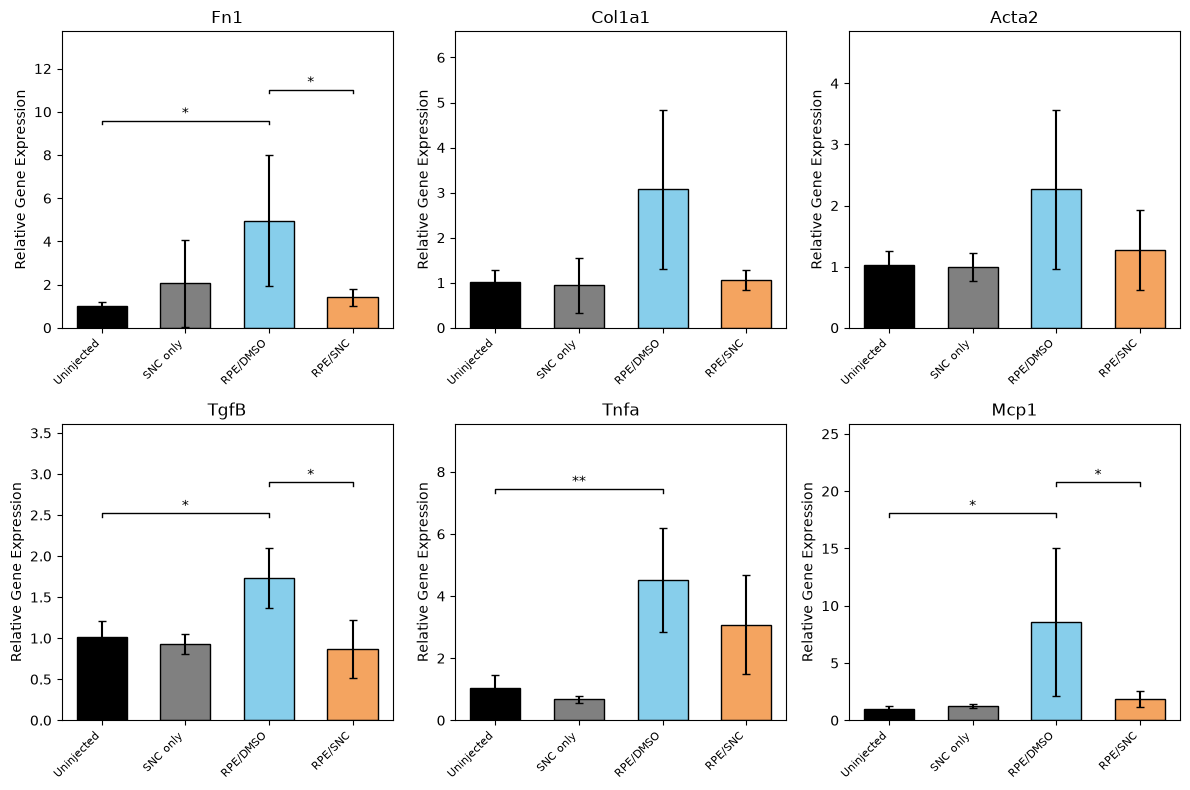

Statistical Test Results:


,Gene,Comparison,p_value,adjusted_p
0,Fn1,Uninjected vs SNC only,0.369403,0.369403
1,Fn1,Uninjected vs RPE/DMSO,0.008787,0.026360
2,Fn1,RPE/DMSO vs RPE/SNC,0.020849,0.041699
3,Col1a1,Uninjected vs SNC only,0.570238,0.570238
4,Col1a1,Uninjected vs RPE/DMSO,0.027269,0.081808
5,Col1a1,RPE/DMSO vs RPE/SNC,0.032747,0.081808
6,Acta2,Uninjected vs SNC only,0.882051,0.882051
7,Acta2,Uninjected vs RPE/DMSO,0.059741,0.179222
8,Acta2,RPE/DMSO vs RPE/SNC,0.154308,0.308615
9,TgfB,Uninjected vs SNC only,0.547816,0.547816


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

relative_expression = 2 ** (-dd_ct)

relative_expression['sample_type'] = (
    relative_expression.index.astype(str)
    .str.replace(r' #\d+$', '', regex=True)
    .str.strip()
)

relative_expression['sample_type'] = relative_expression['sample_type'].replace({
    'DMSO/RPE': 'RPE/DMSO',
    'SNC/RPE': 'RPE/SNC',
    'SNC Only': 'SNC only'
})

mean_expression = relative_expression.groupby('sample_type').mean(numeric_only=True)
std_expression = relative_expression.groupby('sample_type').std(numeric_only=True)

genes = [
    gene for gene in mean_expression.columns
    if gene.strip().lower() != 'gapdh'
]

print("Genes being plotted:", genes)

order = ['Uninjected', 'SNC only', 'RPE/DMSO', 'RPE/SNC']
colors = ['black', 'gray', 'skyblue', 'sandybrown']

print("Available conditions:", mean_expression.index.tolist())

missing = [group for group in order if group not in mean_expression.index]

if missing:
    raise ValueError(f"Missing conditions: {missing}")

# Step 7: Prepare delta Ct values for statistical testing
stats_data = delta_ct.copy()

stats_data['sample_type'] = (
    stats_data.index.astype(str)
    .str.replace(r' #\d+$', '', regex=True)
    .str.strip()
)

stats_data['sample_type'] = stats_data['sample_type'].replace({
    'DMSO/RPE': 'RPE/DMSO',
    'SNC/RPE': 'RPE/SNC',
    'SNC Only': 'SNC only'
})

comparisons = [
    (0, 1),  # Uninjected vs SNC only
    (0, 2),  # Uninjected vs RPE/DMSO
    (2, 3)   # RPE/DMSO vs RPE/SNC
]

fh, ax = plt.subplots(2, 3, figsize=(12, 8), tight_layout=True)

results = []

for i, gene in enumerate(genes[:6]):

    axis = ax.flat[i]

    means = mean_expression.loc[order, gene]
    stds = std_expression.loc[order, gene].fillna(0)

    axis.bar(
        range(4),
        means,
        yerr=stds,
        color=colors,
        edgecolor='black',
        capsize=3,
        width=0.6
    )

    axis.set_title(gene)
    axis.set_ylabel('Relative Gene Expression')
    axis.set_xticks(range(4))
    axis.set_xticklabels(order, rotation=45, ha='right', fontsize=8)

    tests = []

    for group1, group2 in comparisons:

        values1 = stats_data.loc[
            stats_data['sample_type'] == order[group1], gene
        ].dropna()

        values2 = stats_data.loc[
            stats_data['sample_type'] == order[group2], gene
        ].dropna()

        if len(values1) >= 2 and len(values2) >= 2:

            t_stat, p_value = ttest_ind(
                values1,
                values2,
                equal_var=False
            )

            if np.isfinite(p_value):
                tests.append((group1, group2, p_value))

    top = max((means + stds).max(), 0.1)
    step = top * 0.18
    level = 0

    if tests:

        adjusted_p = multipletests(
            [test[2] for test in tests],
            method='holm'
        )[1]

        for (group1, group2, p), p_adj in zip(tests, adjusted_p):

            results.append({
                'Gene': gene,
                'Comparison': f'{order[group1]} vs {order[group2]}',
                'p_value': p,
                'adjusted_p': p_adj
            })

            if p_adj >= 0.05:
                continue

            y = top + step * (level + 1)
            h = step * 0.12

            axis.plot(
                [group1, group1, group2, group2],
                [y, y+h, y+h, y],
                color='black',
                linewidth=1
            )

            if p_adj < 0.001:
                stars = '***'
            elif p_adj < 0.01:
                stars = '**'
            else:
                stars = '*'

            axis.text(
                (group1 + group2) / 2,
                y + h,
                stars,
                ha='center',
                va='bottom',
                fontsize=10
            )

            level += 1

    axis.set_ylim(0, top + step * (level + 2))

for j in range(min(len(genes), 6), 6):
    ax.flat[j].axis('off')

plt.show()

results_df = pd.DataFrame(results)

print("Statistical Test Results:")
display(results_df)


In [ ]:
fh, ax = plt.subplots(2, 3, figsize=(8, 6), tight_layout=True)